![Python Banner](../../Image/05_07_Policy_Learners.png)

# 7.1 Policy Tree

This notebook learns a deterministic treatment rule with PyCausalML. `InteractiveRegressionDML` estimates the average effect from doubly robust scores, and `DRPolicyTree` turns the sign of those scores into an interpretable tree. That is the same policy rule as DoubleML's `policy_tree()`.

## Overview

### What is the policy tree?

PyCausalML's `DRPolicyTree` learns a **deterministic binary treatment policy**. It cross-fits outcome and propensity models, builds a doubly robust score for each unit, and grows a classification tree on the sign of that score, weighted by its absolute value. Leaves assign treatment where the score is positive.

### Key Features

- **Deterministic policies**: Assigns treatment with certainty (0 or 1)
- **Interpretable rules**: Tree structure provides clear decision rules
- **Based on the IRM score**: Uses the same doubly robust score as an interactive regression model
- **Flexible**: Can use any subset of covariates for policy learning
- **Visualization**: The fitted tree can be drawn with scikit-learn

### Business Setting

A policy tree is ideal when:

- **Clear decision rules needed**: Stakeholders need interpretable policies
- **Heterogeneous effects**: Treatment effects vary across customer segments
- **IRM scores are available**: You already estimate effects with a doubly robust model
- **Binary treatment**: Treatment is yes/no (not multi-armed)

Common business applications:

- Customer targeting for marketing campaigns
- Credit approval decisions
- Feature rollout decisions
- Retention offer targeting

## Setup

Install the required packages:

In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

try:
    import pycausalml  # noqa: F401
    print("PyCausalML ready.")
except ImportError:
    root = _repo_root()
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot]"],
    )
    print("PyCausalML installed.")


PyCausalML ready.


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.tree import plot_tree

from pycausalml import DRPolicyTree, InteractiveRegressionDML
from pycausalml.policy_learners import policy_value

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
print("Imported PyCausalML")


def show_policy_tree(model, feature_names, title):
    """Draw the fitted policy tree. Leaves are the assigned treatment."""
    if getattr(model, "policy_", None) is None:
        print(f"{title}: constant policy = {model.constant_}")
        return
    fig, ax = plt.subplots(figsize=(14, 8))
    plot_tree(
        model.policy_,
        feature_names=list(feature_names),
        class_names=["control", "treat"],
        filled=True,
        rounded=True,
        impurity=False,
        ax=ax,
        fontsize=8,
    )
    ax.set_title(title)
    fig.tight_layout()
    plt.show()


Imported PyCausalML


## Example: Synthetic Group Effects

The design follows the DoubleML group-effect example. Treatment effects depend on two covariates, with a different effect in each region.

In [3]:
def group_effect(x):
    """Define group-specific treatment effects."""
    if x[0] <= -0.3:
        te = 2.2
    elif (x[0] >= 0.2) & (x[1] >= 0.4):
        te = 2
    else:
        te = -2
    return te

def create_synthetic_group_data(n_samples=200, n_w=10, support_size=5):
    """
    Creates a simple synthetic example for group effects.
    
    Parameters
    ----------
    n_samples : int
        Number of samples.
    n_w : int
        Dimension of covariates.
    support_size : int
        Number of relevant covariates.
    
    Returns
    -------
    data : pd.DataFrame
        A data frame with covariates, treatment, and outcome.
    covariates : list
        List of covariate column names.
    """
    np.random.seed(42)
    
    # Outcome support
    support_w = np.random.choice(np.arange(n_w), size=support_size, replace=False)
    coefs_w = np.random.uniform(0, 1, size=support_size)
    epsilon_sample = lambda n: np.random.uniform(-1, 1, size=n_samples)
    
    # Treatment support
    support_t = np.random.choice(np.arange(n_w), size=support_size, replace=False)
    coefs_t = np.random.uniform(0, 1, size=support_size)
    eta_sample = lambda n: np.random.uniform(-1, 1, size=n_samples)

    # Generate covariates
    w = np.random.normal(0, 1, size=(n_samples, n_w))
    
    # Group treatment effect
    te = np.apply_along_axis(group_effect, axis=1, arr=w)
    
    # Treatment assignment
    log_odds = np.dot(w[:, support_t], coefs_t) + eta_sample(n_samples)
    t_sigmoid = 1 / (1 + np.exp(-log_odds))
    t = np.array([np.random.binomial(1, p) for p in t_sigmoid])
    
    # Outcome
    y = te * t + np.dot(w[:, support_w], coefs_w) + epsilon_sample(n_samples)

    # Build dataset
    y_df = pd.DataFrame({'y': y})
    t_df = pd.DataFrame({'t': t})
    w_df = pd.DataFrame(data=w, index=np.arange(w.shape[0]),
                        columns=[f'w_{i}' for i in range(1, w.shape[1] + 1)])

    data = pd.concat([y_df, t_df, w_df], axis=1)
    covariates = list(w_df.columns.values)

    return data, covariates

# Generate data
n_samples = 500
n_w = 10
support_size = 5

data, covariates = create_synthetic_group_data(n_samples=n_samples, n_w=n_w, support_size=support_size)
print(data.head())

       y  t    w_1    w_2    w_3    w_4    w_5    w_6    w_7    w_8    w_9  \
0  0.423  0 -0.428 -0.742 -0.703 -2.140 -0.629  0.598  2.559  0.394  0.122   
1  1.796  1 -0.600  0.947  0.291 -0.636 -1.022 -0.162 -0.534 -0.006 -0.229   
2 -0.234  0 -1.265  1.092  2.778  1.194  0.219  0.882 -1.009 -1.583  0.774   
3  0.371  0 -1.347 -0.881 -1.131  0.134  0.582  0.888  0.894  0.755 -0.207   
4 -1.826  0 -1.508  1.100 -0.178 -0.410  1.180 -0.898  0.835  0.297 -1.038   

    w_10  
0 -0.515  
1  0.389  
2 -0.538  
3 -0.623  
4 -0.076  


## Step 1: Fit the IRM model

First fit PyCausalML's interactive regression model. It reports an average treatment effect and a CATE for each row.

In [4]:
# Interactive regression model: doubly robust scores, then a CATE fit
X = data[covariates]
t = data["t"].to_numpy()
y = data["y"].to_numpy()

irm = InteractiveRegressionDML(
    n_splits=3,
    model_y="gbr",
    n_estimators=40,
    random_state=42,
)
print("Training IRM model...")
irm.fit(X, t, y)
ate = irm.average_treatment_effect()
print("IRM average treatment effect")
for key, value in ate.items():
    print(f"  {key}: {value:.3f}")

cate = irm.predict(X)
print(f"CATE mean: {cate.mean():.3f}   CATE sd: {cate.std():.3f}")


Training IRM model...


IRM average treatment effect
  estimate: 0.214
  std.err: 0.133
  ci_lower: -0.046
  ci_upper: 0.475
CATE mean: 0.214   CATE sd: 1.745


## Step 2: Learn Policy Tree

Fit `DRPolicyTree` on `w_1` and `w_2`, the covariates that define the groups:

Training policy value (IPW): 1.143


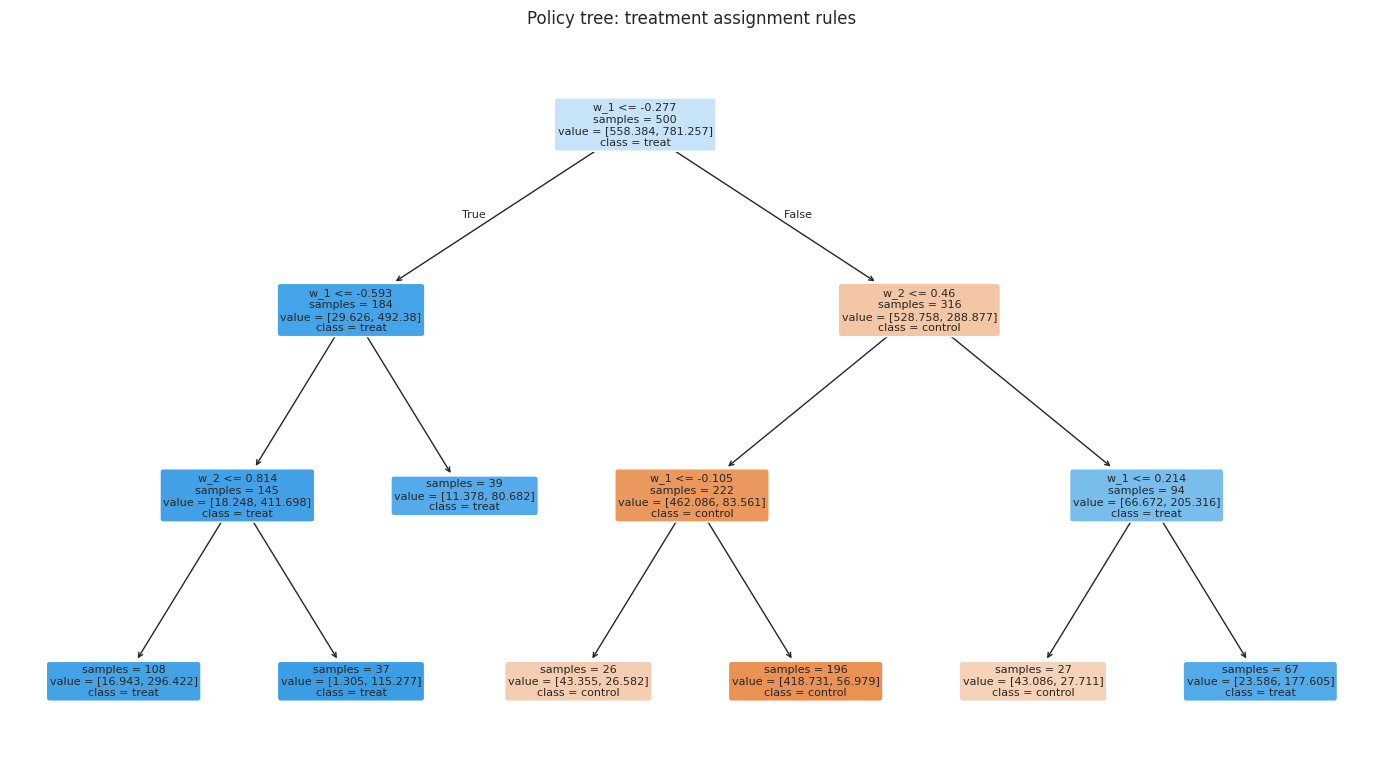

In [5]:
# Policy on the two covariates that define the groups
features = data[["w_1", "w_2"]].copy()
feature_names = list(features.columns)

policy_tree = DRPolicyTree(
    max_depth=3,
    n_splits=3,
    nuisance="gbr",
    n_estimators=40,
    random_state=42,
)
policy_tree.fit(features, t, y)

print(f"Training policy value (IPW): {policy_tree.training_policy_value():.3f}")
show_policy_tree(policy_tree, feature_names, "Policy tree: treatment assignment rules")


The tree shows the decision rules for treatment assignment. Notice how the splits at w_1 ≈ -0.3 and w_1 ≈ 0.2 align with the true group effect thresholds in the data generating process.

## Step 3: Use Policy for Prediction

`predict()` applies the learned policy to new data and returns 0 or 1:

In [6]:
# The same generator, called again, draws a new sample
new_data, _ = create_synthetic_group_data(
    n_samples=n_samples, n_w=n_w, support_size=support_size
)
pred = policy_tree.predict(new_data[["w_1", "w_2"]])
pred_df = new_data[["w_1", "w_2", "t", "y"]].copy()
pred_df["pred_treatment"] = pred

print("Policy predictions:")
print(pred_df.head(10))
print(f"Treatment rate: {pred_df['pred_treatment'].mean():.3f}")


Policy predictions:
     w_1    w_2  t      y  pred_treatment
0 -0.428 -0.742  0  0.423               1
1 -0.600  0.947  1  1.796               1
2 -1.265  1.092  0 -0.234               1
3 -1.347 -0.881  0  0.371               1
4 -1.508  1.100  0 -1.826               1
5  0.973  0.796  1  1.556               1
6  0.904  0.019  0  1.123               0
7  0.257  0.315  1 -1.928               0
8 -2.655  0.346  1 -0.297               1
9 -0.019 -1.674  0 -0.057               0
Treatment rate: 0.502


## Step 4: Policy on All Covariates

We can also learn the policy using all covariates (not just w_1 and w_2):

All-covariate policy value (IPW): 1.099
Feature importance:
  w_1: 0.632
  w_2: 0.360
  w_3: 0.004
  w_4: 0.000
  w_5: 0.000
  w_6: 0.003
  w_7: 0.000
  w_8: 0.000
  w_9: 0.000
  w_10: 0.000


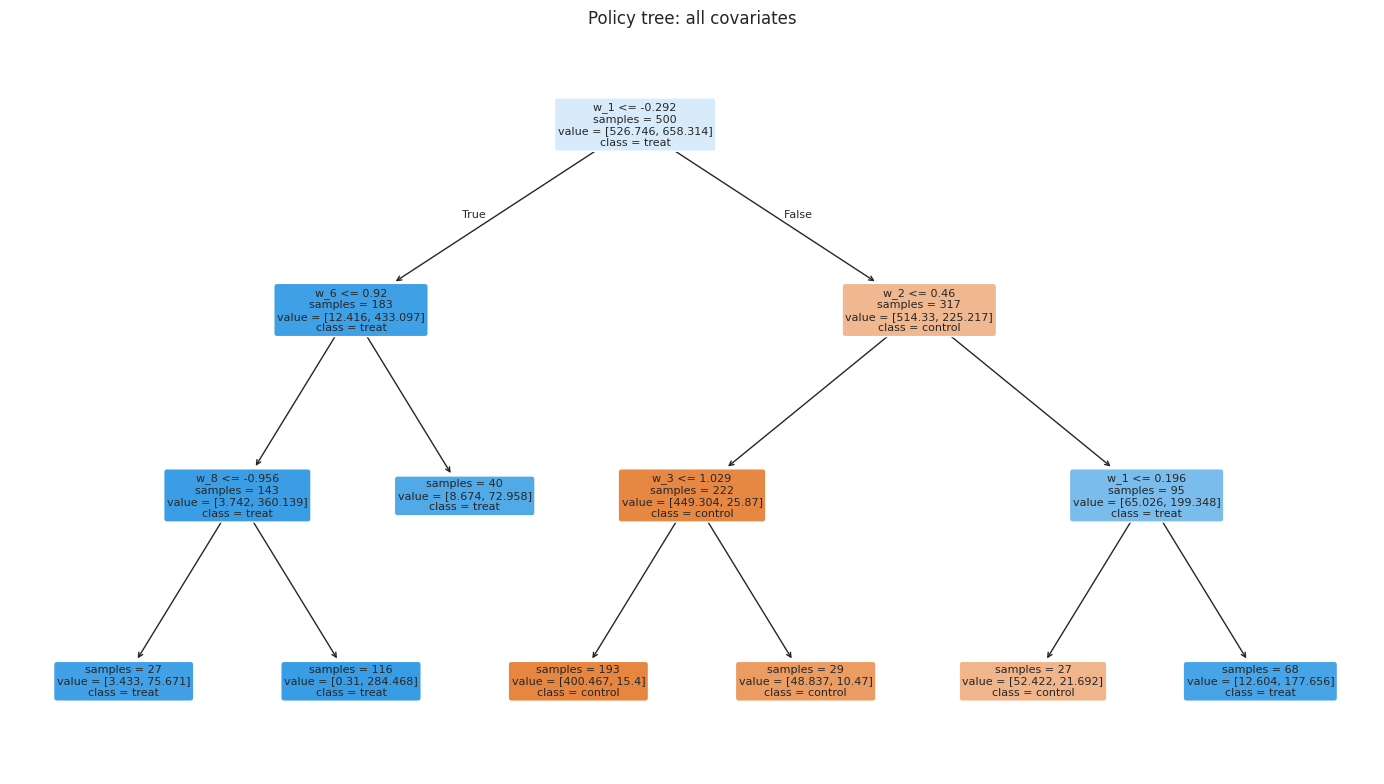

In [7]:
policy_tree_all = DRPolicyTree(
    max_depth=3,
    n_splits=3,
    nuisance="gbr",
    n_estimators=40,
    random_state=42,
)
policy_tree_all.fit(data[covariates], t, y)
print(f"All-covariate policy value (IPW): {policy_tree_all.training_policy_value():.3f}")
print("Feature importance:")
for name, score in zip(covariates, policy_tree_all.feature_importance()):
    print(f"  {name}: {score:.3f}")
show_policy_tree(policy_tree_all, covariates, "Policy tree: all covariates")


## Understanding the Policy

The policy tree provides interpretable rules:

- **Leaf nodes**: Indicate whether to treat (1) or not treat (0)
- **Splits**: Show the covariate thresholds that define treatment regions
- **Samples**: Number of training samples in each region

In our example, the tree correctly identifies the regions where treatment is beneficial (positive CATE) vs. harmful (negative CATE).

## Hyperparameter Tuning

Key hyperparameters for policy learning:

- **depth**: Tree depth (controls complexity)
- **min_samples_leaf**: Minimum samples per leaf (controls overfitting)
- **max_features**: Features to consider for splits

Deeper trees can capture more complex patterns but may overfit. Shallower trees are more interpretable but may miss important heterogeneity.

In [8]:
for depth in [2, 3, 4, 5]:
    pt = DRPolicyTree(
        max_depth=depth,
        n_splits=2,
        nuisance="gbr",
        n_estimators=30,
        random_state=42,
    )
    pt.fit(features, t, y)
    rate = pt.predict(features).mean()
    print(
        f"Depth {depth}: treatment rate = {rate:.3f}, "
        f"policy value = {pt.training_policy_value():.3f}"
    )


Depth 2: treatment rate = 0.570, policy value = 1.150
Depth 3: treatment rate = 0.506, policy value = 1.184


Depth 4: treatment rate = 0.506, policy value = 1.184
Depth 5: treatment rate = 0.506, policy value = 1.184


## Common Pitfalls

### 1. Overfitting

Deep trees may overfit to noise in the CATE estimates.

**Solution**: Use shallower trees, cross-validation, or ensemble methods (policy forests).

### 2. Wrong Feature Selection

Using irrelevant features can lead to poor policies.

**Solution**: Use domain knowledge or feature importance from the IRM model to select relevant features.

### 3. Ignoring Uncertainty

Policy trees don't account for uncertainty in CATE estimates.

**Solution**: Use policy forests (ensembles) or bootstrap to quantify uncertainty.

## When to use a policy tree

`DRPolicyTree` is the right choice when:

- **Interpretable rules needed**: Stakeholders need clear decision rules
- **IRM scores are enough**: A single tree on the doubly robust score is the decision rule you want
- **Binary treatment**: Treatment is yes/no
- **Moderate heterogeneity**: Effects vary but not extremely complex

Consider alternatives when:

- Complex heterogeneity → Policy forests or neural policies
- Multi-armed treatment → Policy forests with multi-arm support
- Uncertainty quantification needed → Bootstrap or Bayesian methods

## Summary

PyCausalML's policy tree is a simple, interpretable way to turn doubly robust scores into a treatment rule.

**Key takeaways:**

- Policy trees learn deterministic treatment rules from the sign of the doubly robust score
- `InteractiveRegressionDML` estimates the average effect; `DRPolicyTree` assigns treatment
- Provide interpretable decision rules through tree structure
- Can use any subset of covariates for policy learning
- Deeper trees capture more complexity but may overfit
- Always validate policies on held-out data
- Consider policy forests for more robust policies

## Scientific Terminology

Plain-language definitions for the terms in this tutorial are in the [scientific terminology glossary](../00-scientific-terminology-glossary.qmd).
